In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"])

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'open_clip_torch'], returncode=0)

In [2]:
%%writefile /kaggle/working/dressme_core.py
"""dressme_core : code PARTAGE entre le notebook d'entrainement et l'interface.
Le notebook ecrit ce fichier, l'interface l'importe : meme code des deux cotes."""
import re, json
import torch, torch.nn as nn, torch.nn.functional as F

K = 5                                   # max d'articles : 4 vetements + 1 accessoire
ACC_CATS = {"accessory", "bag"}         # categories comptees comme "accessoire" (5e slot)
DEFAULT_THR = {"p_odd": 0.5, "delta": -0.5}

# ----------------------------------------------------------------------------------------
# 1) CATEGORIES : on cherche le NOM PRINCIPAL = dernier mot reconnu de la description
#    ("knit midi skirt" -> skirt ; "baggy jeans" -> jeans ; "leather belt bag" -> bag)
# ----------------------------------------------------------------------------------------
CAT_WORDS = {
    "shoes": "sneaker boot bootie sandal loafer pump heel flat mule shoe slipper slide oxford derby "
             "espadrille trainer wedge clog slingback moccasin".split(),
    "bag": "bag handbag tote clutch backpack purse pouch satchel crossbody".split(),
    "dress": "dress gown jumpsuit playsuit kaftan caftan".split(),
    "outer": "coat jacket blazer parka trench vest gilet cape poncho blouson bomber anorak overcoat "
             "puffer windbreaker".split(),
    "top": "t-shirt shirt blouse sweater top knit cardigan hoodie sweatshirt polo tank bodysuit jumper "
           "turtleneck tee camisole tunic pullover".split(),
    "bottom": "pant pants trouser trousers jean jeans skirt short shorts legging leggings jogger joggers "
              "sweatpant sweatpants chino chinos culotte culottes bermuda".split(),
    "accessory": "belt scarf hat sunglasses glasses glove cap beanie necklace bracelet earring ring watch "
                 "tie sock tights headband brooch bandana foulard shawl stole choker pendant anklet "
                 "cuff wallet".split(),
}
WORD2CAT = {w: c for c, ws in CAT_WORDS.items() for w in ws}


def category(desc):
    d = (desc or "").lower()
    d = re.split(r"\bwith\b|\bfeaturing\b|,|\(", d)[0] or d      # on coupe "... with leather trim"
    toks = re.findall(r"[a-z]+", d)
    for t in reversed(toks):
        for cand in (t, t[:-1] if t.endswith("s") else t, t[:-2] if t.endswith("es") else t):
            if cand in WORD2CAT:
                return WORD2CAT[cand]
    return "other"


# ----------------------------------------------------------------------------------------
# 2) SAISONS / STYLES NORMALISES ("Spring/Summer" == "Spring, Summer" ; "Smart Casual Style" ~ "Smart Casual")
# ----------------------------------------------------------------------------------------
def _as_text(x):
    if isinstance(x, (list, tuple)):
        return " ".join(map(str, x))
    return str(x or "")


def norm_season(s):
    s = _as_text(s).lower()
    out = set()
    if "spring" in s: out.add("spring")
    if "summer" in s: out.add("summer")
    if "autumn" in s or "fall" in s: out.add("autumn")
    if "winter" in s: out.add("winter")
    return frozenset(out)                      # vide = inconnu


def seasons_disjoint(a, b):                    # les deux connues ET aucune saison commune
    return bool(a) and bool(b) and not (a & b)


def seasons_compatible(a, b):                  # au moins une saison commune
    return bool(a & b)


def norm_style(s):
    toks = set(re.findall(r"[a-z]+", _as_text(s).lower())) - {"style", "other", "unknown"}
    return frozenset(toks)


def style_close(a, b):                         # Jaccard >= 0.5 -> meme style
    if not a or not b:
        return True                            # inconnu : on ne pretend pas qu'ils different
    return len(a & b) / len(a | b) >= 0.5


# ----------------------------------------------------------------------------------------
# 3) MODELE
# ----------------------------------------------------------------------------------------
class OutfitScorer(nn.Module):
    def __init__(self, visual, d=256, heads=4, layers=2):
        super().__init__()
        self.visual = visual
        self.proj = nn.Linear(512, d)
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True)
        self.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.score_head = nn.Linear(d, 1)
        self.none_head = nn.Linear(d, 1)
        self.odd_head = nn.Linear(d, 1)

    def encode_images(self, x):
        return F.normalize(self.visual(x).float(), dim=-1)

    def forward(self, emb, mask):              # emb (B,k,512) ; mask (B,k) vrai = article present
        B = emb.shape[0]
        x = torch.cat([self.cls.expand(B, -1, -1), self.proj(emb.float())], 1)
        pad = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=emb.device), ~mask], 1)
        h = self.tf(x, src_key_padding_mask=pad)
        score = 10 * torch.sigmoid(self.score_head(h[:, 0]).squeeze(-1))
        odd_items = self.odd_head(h[:, 1:]).squeeze(-1).masked_fill(~mask, -1e4)
        odd = torch.cat([self.none_head(h[:, 0]), odd_items], 1)       # (B, 1+k) ; 0 = aucun intrus
        return score, odd


@torch.no_grad()
def score_rows(model, E, rows, bs=256):
    """Note de chaque tenue. rows = liste de listes d'indices dans la table E (longueurs variables)."""
    model.eval(); dev = E.device; out = []
    for i in range(0, len(rows), bs):
        chunk = rows[i:i + bs]; kmax = max(len(r) for r in chunk)
        t = torch.zeros(len(chunk), kmax, dtype=torch.long, device=dev)
        m = torch.zeros(len(chunk), kmax, dtype=torch.bool, device=dev)
        for b, r in enumerate(chunk):
            t[b, :len(r)] = torch.tensor(r, device=dev); m[b, :len(r)] = True
        s, _ = model(E[t], m); out.append(s.cpu())
    return torch.cat(out) if out else torch.zeros(0)


# ----------------------------------------------------------------------------------------
# 4) VERIFICATION D'UN ACCESSOIRE : match ou non ?
# ----------------------------------------------------------------------------------------
@torch.no_grad()
def check_accessory(model, base_emb, acc_emb, thr=None):
    """base_emb (n,512) = vetements SANS accessoire (1 a 4) ; acc_emb (512,) = accessoire ajoute.
    Compare la tenue avec et sans l'accessoire.
      delta = note(avec) - note(sans) ; p_odd = proba que l'accessoire soit l'intrus.
    MATCH si p_odd < seuil ET delta > seuil ; NO MATCH si les deux signaux sont mauvais ; sinon BORDERLINE."""
    thr = thr or DEFAULT_THR
    n = int(base_emb.shape[0])
    if not 1 <= n <= K - 1:
        raise ValueError(f"Il faut entre 1 et {K - 1} vetements (recu {n}) + 1 accessoire.")
    model.eval(); dev = base_emb.device
    emb = torch.zeros(2, n + 1, base_emb.shape[1], device=dev)
    emb[:, :n] = base_emb.float(); emb[1, n] = acc_emb.float()
    mask = torch.ones(2, n + 1, dtype=torch.bool, device=dev); mask[0, n] = False
    sc, ol = model(emb, mask)
    p_odd = torch.softmax(ol[1], -1)[n + 1].item()           # indice 0 = "aucun intrus", puis 1 + position
    s_wo, s_with = sc[0].item(), sc[1].item()
    delta = s_with - s_wo
    ok_p, ok_d = p_odd < thr["p_odd"], delta > thr["delta"]
    verdict = "MATCH" if (ok_p and ok_d) else ("NO MATCH" if (not ok_p and not ok_d) else "BORDERLINE")
    return dict(verdict=verdict, match=bool(ok_p and ok_d), score_without=s_wo, score_with=s_with,
                delta=delta, p_odd=p_odd, base_ok=s_wo >= 5)


# ----------------------------------------------------------------------------------------
# 5) CHARGEMENT POUR L'INTERFACE
# ----------------------------------------------------------------------------------------
def load_scorer(path, device=None):
    """Recharge le modele exporte. Retourne (model, preprocess, config)."""
    import open_clip
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    cfg = json.load(open(f"{path}/config.json"))
    clip_model, _, preprocess = open_clip.create_model_and_transforms(cfg["clip_name"],
                                                                      pretrained=cfg["clip_pretrained"])
    visual = clip_model.visual; del clip_model
    visual.load_state_dict(torch.load(f"{path}/visual.pt", map_location="cpu"))      # CLIP FINE-TUNE
    model = OutfitScorer(visual, **cfg["scorer"])
    missing, unexpected = model.load_state_dict(torch.load(f"{path}/scorer.pt", map_location="cpu"), strict=False)
    assert not unexpected and all(k.startswith("visual.") for k in missing), (missing, unexpected)
    return model.to(device).eval(), preprocess, cfg


@torch.no_grad()
def embed_images(model, preprocess, pil_images, device=None):
    """Vecteurs CLIP (fine-tune) de nouvelles photos, ex : l'accessoire que l'utilisateur ajoute."""
    device = device or next(model.parameters()).device
    ims = []
    for im in pil_images:
        im = im.convert("RGB").copy(); im.thumbnail((448, 448)); ims.append(preprocess(im))   # comme a l'entrainement
    model.eval()
    return model.encode_images(torch.stack(ims).to(device).float())

Writing /kaggle/working/dressme_core.py


In [4]:
import os, json, random, tarfile, copy, re, sys, shutil
from collections import defaultdict, Counter
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download
import open_clip

sys.path.insert(0, "/kaggle/working")
import dressme_core as core
from dressme_core import (K, ACC_CATS, OutfitScorer, category, norm_season, norm_style,
                          seasons_disjoint, seasons_compatible, style_close)

assert torch.cuda.is_available(), "Pas de GPU : Session options > Accelerator > GPU T4"
dev, use_amp = "cuda", True
random.seed(0); np.random.seed(0); torch.manual_seed(0)
login(UserSecretsClient().get_secret("hf_syrine"))     # identification aupres de Hugging Face

REPO = "ArtmeScienceLab/Garments2Look"
SHARDS = [17, 16]      # archives d'images. 17 = la plus legere (2.3 Go). Plus d'archives = plus d'accessoires.
                       # Si "No space left" ou trop long : repasser a [17].
OUT = "/kaggle/working/g2l_images"
os.makedirs(OUT, exist_ok=True)

In [5]:
avail = set()
for shard in SHARDS:
    tar_path = hf_hub_download(REPO, f"mytheresa/images-{shard:05d}.tar.gz",
                               repo_type="dataset", local_dir="/kaggle/working/g2l_dl")
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar:
            parts = m.name.split("/")
            if m.isfile() and len(parts) == 4 and parts[3] == parts[2] + ".jpg":
                im = Image.open(tar.extractfile(m)).convert("RGB")
                im.thumbnail((448, 448)); im.save(f"{OUT}/{parts[2]}.jpg", quality=90)
                avail.add(parts[2])
    os.remove(tar_path)
print(len(avail), "articles avec photo")

mytheresa/images-00017.tar.gz: reconstructing file:   0%|          |  0.00B / 2.34GB            

mytheresa/images-00017.tar.gz: downloading bytes:           |  0.00B            

mytheresa/images-00016.tar.gz: reconstructing file:   0%|          |  0.00B / 10.4GB            

mytheresa/images-00016.tar.gz: downloading bytes:           |  0.00B            

4386 articles avec photo


In [6]:
# %% DONNEES : tenues officielles, categories corrigees, saisons/styles normalises, split SANS FUITE
data = json.load(open(hf_hub_download(REPO, "mytheresa_outfit_v1.0_2512.json", repo_type="dataset")))

def txt(season):                                   # affichage d'une saison normalisee
    return "/".join(sorted(season)) if season else "unknown"

desc_of, raw_outfits = {}, []
for oid, o in data.items():
    for c, d in o["outfit"].items():
        desc_of.setdefault(c, d)
    if o["is_official_outfit"] and o["is_official_look"]:
        codes = [c for c in o["outfit"] if c in avail]
        if len(codes) >= 3:
            info = o["outfit_info"]
            season, style = norm_season(info.get("season")), norm_style(info.get("style"))
            raw_outfits.append(dict(codes=codes, season=season, style=style,
                                    season_txt=txt(season), style_txt=" ".join(sorted(style)) or "other",
                                    colors=list(info.get("color_palette", []) or [])))
print(len(raw_outfits), "tenues officielles avec au moins 3 photos")
assert len(raw_outfits) >= 60, "Trop peu de tenues : ajoute une archive dans SHARDS"

used = sorted({c for of in raw_outfits for c in of["codes"]})
code2idx = {c: i for i, c in enumerate(used)}
DESC = [desc_of[c] for c in used]
CAT = [category(d) for d in DESC]
for of in raw_outfits:
    of["items"] = [code2idx[c] for c in of["codes"]]

# --- split par COMPOSANTES CONNEXES : deux tenues qui partagent un article restent ensemble -> zero fuite
def split_by_components(outfits, fr_test=0.2, fr_val=0.1, seed=0):
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for of in outfits:
        for it in of["items"][1:]:
            ra, rb = find(it), find(of["items"][0])
            if ra != rb: parent[ra] = rb
    groups = defaultdict(list)
    for of in outfits:
        groups[find(of["items"][0])].append(of)
    groups = sorted(groups.values(), key=len, reverse=True)
    train, val, test = list(groups[0]), [], []              # le plus gros groupe va dans train
    rest = groups[1:]; random.Random(seed).shuffle(rest)
    N = len(outfits)
    for g in rest:
        if len(test) < fr_test * N: test += g
        elif len(val) < fr_val * N: val += g
        else: train += g
    return train, val, test, len(groups[0])

pool_train, pool_val, pool_test, biggest = split_by_components(raw_outfits)
def items_of(pool): return {i for of in pool for i in of["items"]}
assert not (items_of(pool_train) & items_of(pool_test)) and not (items_of(pool_train) & items_of(pool_val)) \
       and not (items_of(pool_val) & items_of(pool_test)), "fuite train/val/test"
print(f"{len(used)} articles | train {len(pool_train)} | val {len(pool_val)} | test {len(pool_test)} tenues "
      f"(plus gros groupe : {biggest}) -> AUCUN article commun entre les trois jeux")
if min(len(pool_val), len(pool_test)) < 8:
    print("ATTENTION : val/test tres petits -> metriques tres bruitees. Ajoute des archives dans SHARDS.")

cnt = Counter(CAT)
n_acc = sum(cnt[c] for c in ACC_CATS)
print("Categories :", dict(sorted(cnt.items())))
print(f"Accessoires (accessory + bag) : {n_acc} articles | tenues avec accessoire : "
      f"{sum(any(CAT[i] in ACC_CATS for i in of['items']) for of in raw_outfits)}/{len(raw_outfits)}")
if n_acc < 30:
    print("ATTENTION : moins de 30 accessoires -> la verification d'accessoire sera peu fiable. "
          "Ajoute des archives dans SHARDS (ex : [17, 16, 15]).")
print("Saisons :", Counter(of["season_txt"] for of in raw_outfits).most_common(8))
print("Styles  :", Counter(of["style_txt"] for of in raw_outfits).most_common(8))
assert len(set().union(*[of["season"] for of in pool_train])) >= 2, "une seule saison dans train : ajoute une archive"

mytheresa_outfit_v1.0_2512.json: reconstructing file:   0%|          |  0.00B /  102MB            

mytheresa_outfit_v1.0_2512.json: downloading bytes:           |  0.00B            

467 tenues officielles avec au moins 3 photos
653 articles | train 322 | val 50 | test 95 tenues (plus gros groupe : 39) -> AUCUN article commun entre les trois jeux
Categories : {'accessory': 25, 'bag': 56, 'bottom': 138, 'dress': 21, 'other': 32, 'outer': 104, 'shoes': 106, 'top': 171}
Accessoires (accessory + bag) : 81 articles | tenues avec accessoire : 171/467
Saisons : [('autumn', 240), ('spring', 73), ('summer', 34), ('spring/summer', 32), ('autumn/winter', 29), ('autumn/spring', 23), ('winter', 19), ('unknown', 12)]
Styles  : [('casual smart', 56), ('casual', 40), ('athleisure', 36), ('chic contemporary', 25), ('casual contemporary', 22), ('casual chic', 18), ('chic elegant', 15), ('casual sophisticated', 12)]


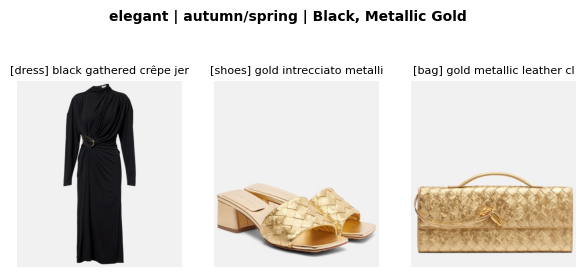

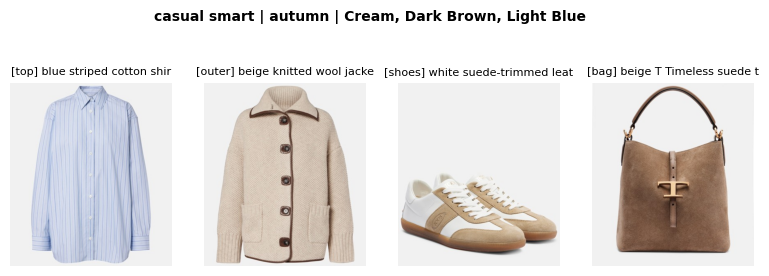

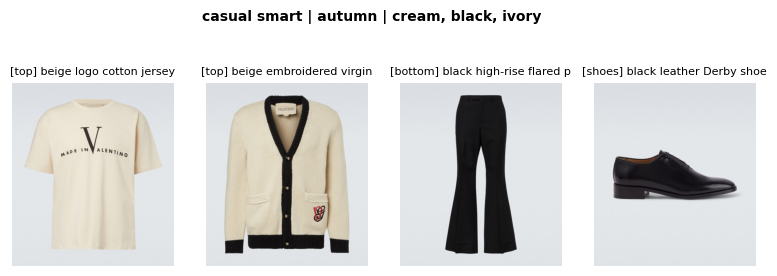

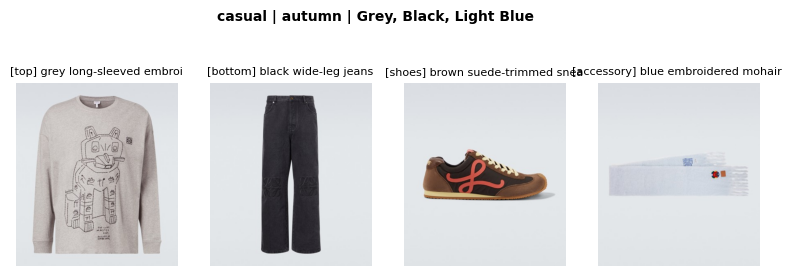

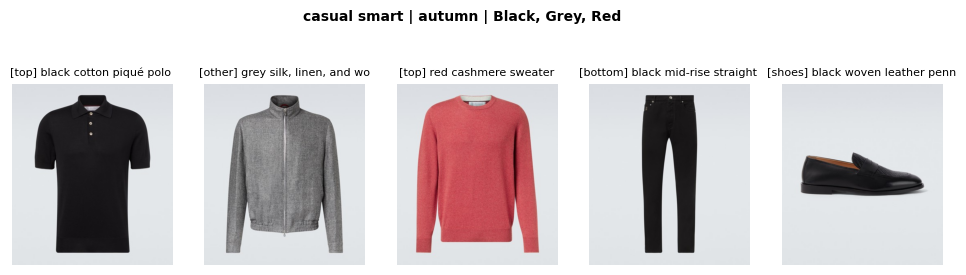

In [7]:
# %% VOIR LES DONNEES : 5 tenues reelles (photos + style, saison, couleurs)
for of in random.sample(raw_outfits, 5):
    n = min(5, len(of["items"]))
    fig, axs = plt.subplots(1, n, figsize=(2.4 * n, 3.4), squeeze=False)
    fig.suptitle(f"{of['style_txt']} | {of['season_txt']} | {', '.join(of['colors'][:3])}", fontweight="bold", fontsize=10)
    for c in range(n):
        ax = axs[0][c]; ax.imshow(Image.open(f"{OUT}/{of['codes'][c]}.jpg")); ax.axis("off")
        ax.set_title(f"[{CAT[of['items'][c]]}] " + DESC[of["items"][c]][:24], fontsize=8)
    plt.show()

In [8]:
clip_model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
visual = clip_model.visual.to(dev)
del clip_model
IMG = torch.stack([preprocess(Image.open(f"{OUT}/{c}.jpg").convert("RGB")) for c in used]).half()
print("images :", tuple(IMG.shape))

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

images : (653, 3, 224, 224)


In [9]:
# %% FABRICATION DES EXEMPLES (notes) + EVALUATION
#   EXCELLENT (9) : vraie tenue du site
#   PASSABLE  (6) : un article remplace par un article de saison COMPATIBLE mais de style DIFFERENT
#   MAUVAIS   (2) : un article remplace par un article d'une saison INCOMPATIBLE
# L'article touche peut etre un VETEMENT, l'ACCESSOIRE, ou un accessoire AJOUTE a une tenue de 4 articles.
P_ACC_REPLACE = 0.4      # si la tenue a un accessoire : proba de corrompre l'accessoire
P_ACC_INSERT = 0.3       # si la tenue n'en a pas : proba d'AJOUTER un accessoire incompatible

def split_items(of):
    clothes = [it for it in of["items"] if CAT[it] not in ACC_CATS]
    accs = [it for it in of["items"] if CAT[it] in ACC_CATS]
    return clothes, accs

def make_sample(tier, pool):
    for _ in range(300):
        of = random.choice(pool)
        clothes, accs = split_items(of)
        if len(clothes) < 2:
            continue
        base = random.sample(clothes, min(4, len(clothes)))          # 4 vetements max
        acc = random.choice(accs) if accs else None                  # 1 accessoire max (5e slot)
        items = base + ([acc] if acc is not None else [])
        if tier == 2:
            return dict(items=items, score=9.0, odd=0, orig=None)
        if tier == 0:
            ok = lambda o2: seasons_disjoint(o2["season"], of["season"])
        else:
            ok = lambda o2: (seasons_compatible(o2["season"], of["season"]) and bool(o2["style"])
                             and bool(of["style"]) and not style_close(o2["style"], of["style"]))
        def cands(cat_):
            return [it for o2 in pool if ok(o2) for it in o2["items"] if CAT[it] == cat_ and it not in of["items"]]
        score = 2.0 if tier == 0 else 6.0
        r = random.random()
        if acc is not None and r < P_ACC_REPLACE:                    # a) accessoire remplace
            c = cands(CAT[acc])
            if c:
                j = len(items) - 1; items[j] = random.choice(c)
                return dict(items=items, score=score, odd=j + 1, orig=acc)
        if acc is None and r < P_ACC_INSERT:                         # b) accessoire incompatible AJOUTE
            c = [it for cat_ in sorted(ACC_CATS) for it in cands(cat_)]
            if c:
                items = items + [random.choice(c)]
                return dict(items=items, score=score, odd=len(items), orig=None)
        known = [j for j, it in enumerate(base) if CAT[it] != "other"]   # c) vetement remplace
        if not known:
            continue
        j = random.choice(known); orig = items[j]
        c = cands(CAT[orig])
        if c:
            items = items[:]; items[j] = random.choice(c)
            return dict(items=items, score=score, odd=j + 1, orig=orig)
    return None                                                      # pas assez de variete dans ce pool

def draw_samples(pool, reps, tiers=(2, 1, 0)):
    out = [make_sample(t, pool) for _ in range(len(pool) * reps) for t in tiers]
    return [s for s in out if s is not None]

def build_batch(samples):
    B = len(samples)
    items = torch.zeros(B, K, dtype=torch.long); mask = torch.zeros(B, K, dtype=torch.bool)
    for b, s in enumerate(samples):
        n = len(s["items"]); items[b, :n] = torch.tensor(s["items"]); mask[b, :n] = True
    return (items, mask, torch.tensor([s["score"] for s in samples]), torch.tensor([s["odd"] for s in samples]))

def loss_fn(score, odd_logits, y, odd):
    return F.smooth_l1_loss(score, y) + F.cross_entropy(odd_logits, odd)

# --- PAIRES : tenue abimee + MEME tenue reparee (article d'origine remis, ou accessoire ajoute retire) ---
RANK_W = 1.0
def make_pair(tier, pool):
    bad = make_sample(tier, pool)
    if bad is None:
        return None
    j = bad["odd"] - 1
    good_items = bad["items"][:]
    if bad["orig"] is None: good_items.pop(j)          # accessoire ajoute -> on le retire
    else: good_items[j] = bad["orig"]
    return dict(good=dict(items=good_items, score=9.0, odd=0, orig=None), bad=bad,
                margin=0.5 * (9.0 - bad["score"]))

def draw_pairs(pool, reps):
    ps = [make_pair(t, pool) for _ in range(len(pool) * reps) for t in (1, 0)]
    return [p for p in ps if p is not None]

def pair_batch(pairs):
    items, mask, y, odd = build_batch([p["good"] for p in pairs] + [p["bad"] for p in pairs])
    return items, mask, y, odd, torch.tensor([p["margin"] for p in pairs])

def pair_loss(score, ol, y, odd, margin):
    B = len(margin)
    rank = F.relu(margin - (score[:B] - score[B:])).mean()
    return loss_fn(score, ol, y, odd) + RANK_W * rank

@torch.no_grad()
def compute_table(model, bs=128):
    model.eval(); out = []
    for i in range(0, len(IMG), bs):
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            out.append(model.encode_images(IMG[i:i + bs].to(dev).float()))
    return torch.cat(out)

def tier_of(s): return 0 if s < 5 else (1 if s < 8 else 2)

def auc_score(y_true, s):
    y_true, s = np.array(y_true), np.array(s)
    pos, neg = s[y_true == 1], s[y_true == 0]
    if len(pos) == 0 or len(neg) == 0: return float("nan")
    return float((pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean())

def build_catalog(items):
    d = defaultdict(list)
    for it in sorted(items): d[CAT[it]].append(it)
    return d

REP_EVAL, REP_TRAIN = 4, 3
random.seed(123)
val_samples = draw_samples(pool_val, REP_EVAL)           # sert a CHOISIR (meilleure epoque, seuils)
test_samples = draw_samples(pool_test, REP_EVAL)         # sert uniquement a MESURER, jamais a choisir
CATALOG_VAL = build_catalog(items_of(pool_val)); CATALOG_TEST = build_catalog(items_of(pool_test))
CATALOG_ALL = build_catalog(range(len(used)))            # catalogue complet : suggestions pour l'utilisateur
select_ok = len(val_samples) >= 20
for name, sm in (("val", val_samples), ("test", test_samples)):
    print(name, len(sm), "exemples | par niveau :", dict(Counter(tier_of(s["score"]) for s in sm)),
          "| accessoire touche :", sum(s["odd"] > 0 and CAT[s["items"][s["odd"] - 1]] in ACC_CATS for s in sm))
if not select_ok:
    print("ATTENTION : jeu de validation trop petit -> pas de selection de la meilleure epoque.")

@torch.no_grad()
def suggest(model, E, items, pos, catalog):
    model.eval()
    cands = [c for c in catalog.get(CAT[items[pos]], []) if c not in items]
    if not cands:
        return [], [], None
    rows = [items[:pos] + [c] + items[pos + 1:] for c in cands] + [items]
    sc = core.score_rows(model, E, rows); old = sc[-1].item(); sc = sc[:-1]
    order = sc.argsort(descending=True).tolist()
    return [cands[i] for i in order], sc[order].tolist(), old

@torch.no_grad()
def evaluate(model, E, samples, catalog):
    model.eval()
    items, mask, y, odd = build_batch(samples)
    s, ol = model(E[items.to(dev)], mask.to(dev)); s, ol = s.cpu(), ol.cpu()
    acc3 = float(np.mean([tier_of(a) == tier_of(b) for a, b in zip(s.tolist(), y.tolist())]))
    auc = auc_score([int(v == 9.0) for v in y.tolist()], s.tolist())
    bad = [i for i, sm in enumerate(samples) if sm["odd"] > 0]
    pred_odd = ol.argmax(1)
    loc = {i for i in bad if pred_odd[i].item() == samples[i]["odd"]}
    bad_acc = [i for i in bad if CAT[samples[i]["items"][samples[i]["odd"] - 1]] in ACC_CATS]
    hits, rand, n_r = 0, 0.0, 0
    for i in loc:
        sm = samples[i]
        if sm["orig"] is None: continue
        cands, _, _ = suggest(model, E, sm["items"], sm["odd"] - 1, catalog)
        if cands:
            hits += int(sm["orig"] in cands[:5]); rand += min(5, len(cands)) / len(cands); n_r += 1
    rest = []
    for i in bad:                                         # on repare la tenue : la note doit monter
        sm = samples[i]; it = sm["items"][:]; j = sm["odd"] - 1
        if sm["orig"] is None: it.pop(j)
        else: it[j] = sm["orig"]
        rest.append(it)
    delta = core.score_rows(model, E, rest) - s[bad] if bad else torch.zeros(1)
    n_r = max(n_r, 1)
    return dict(MAE=(s - y).abs().mean().item(), acc3=acc3, AUC=auc,
                intrus=len(loc) / max(len(bad), 1),
                intrus_acc=sum(i in loc for i in bad_acc) / max(len(bad_acc), 1),
                recall5=hits / n_r, hasard5=rand / n_r,
                retour=float((delta > 0.3).float().mean()), gain=float(delta.mean()))

def show(name, m):
    print(f"{name:<28} MAE {m['MAE']:.2f} | niveau {m['acc3']:.2f} | AUC {m['AUC']:.2f} | "
          f"intrus {m['intrus']:.2f} (dont accessoire {m['intrus_acc']:.2f}) | "
          f"remplacement top-5 {m['recall5']:.2f} (hasard {m['hasard5']:.2f})")
    print(f"{'':<28} article repare : la note monte dans {m['retour']:.2f} des cas (gain moyen {m['gain']:+.1f})")

val 600 exemples | par niveau : {2: 200, 1: 200, 0: 200} | accessoire touche : 94
test 1140 exemples | par niveau : {2: 380, 1: 380, 0: 380} | accessoire touche : 270


In [10]:
# %% MODELE + MESURE AVANT ENTRAINEMENT (point de depart : doit etre proche du hasard)
SCORER_CFG = dict(d=256, heads=4, layers=2)
model = OutfitScorer(visual, **SCORER_CFG).to(dev)
for p in model.visual.parameters():
    p.requires_grad = False
n_clip = sum(p.numel() for p in model.visual.parameters())
n_head = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("visual."))
print(f"CLIP : {n_clip / 1e6:.1f} M parametres (gele) | Outfit Transformer + tetes : {n_head / 1e6:.2f} M (entraines)")
E0 = compute_table(model)                                   # CLIP d'origine
results = {"1. avant entrainement": evaluate(model, E0, test_samples, CATALOG_TEST)}
show("1. avant entrainement", results["1. avant entrainement"])

CLIP : 87.8 M parametres (gele) | Outfit Transformer + tetes : 1.71 M (entraines)
1. avant entrainement        MAE 2.44 | niveau 0.33 | AUC 0.49 | intrus 0.29 (dont accessoire 0.21) | remplacement top-5 0.23 (hasard 0.28)
                             article repare : la note monte dans 0.06 des cas (gain moyen -0.0)


epoque   5/40  loss 2.226 | val : niveau 0.50  AUC 0.82
epoque  10/40  loss 1.744 | val : niveau 0.38  AUC 0.79
epoque  15/40  loss 1.504 | val : niveau 0.47  AUC 0.77
epoque  20/40  loss 1.246 | val : niveau 0.46  AUC 0.75
epoque  25/40  loss 1.124 | val : niveau 0.49  AUC 0.79
epoque  30/40  loss 1.009 | val : niveau 0.48  AUC 0.74
epoque  35/40  loss 0.995 | val : niveau 0.36  AUC 0.68
epoque  40/40  loss 0.902 | val : niveau 0.55  AUC 0.71
-> meilleure epoque retenue : 5 (AUC val 0.82)
2. transformer entraine      MAE 2.64 | niveau 0.44 | AUC 0.73 | intrus 0.37 (dont accessoire 0.40) | remplacement top-5 0.69 (hasard 0.32)
                             article repare : la note monte dans 0.62 des cas (gain moyen +1.6)


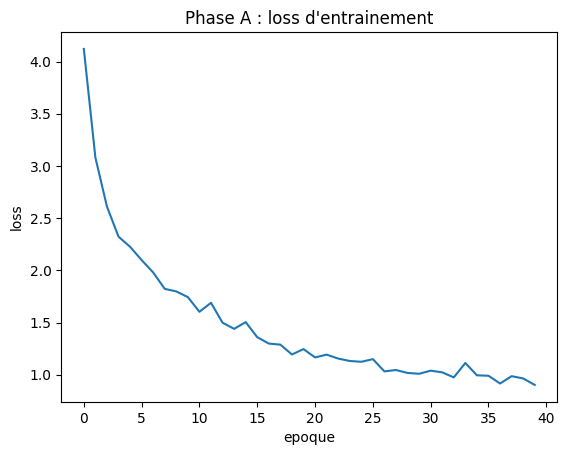

In [11]:
# %% PHASE A : entrainement du transformer (CLIP gele). Nouvelles tenues abimees a CHAQUE epoque.
# On garde l'epoque qui a la meilleure AUC sur la VALIDATION (jamais sur le test).
EPOCHS_A, PAIRS_A = 40, 16
E = E0
params = [p for n, p in model.named_parameters() if not n.startswith("visual.")]
opt = torch.optim.AdamW(params, lr=3e-4, weight_decay=0.01)
hist_a, best_val, best_state, best_ep = [], -1.0, None, -1
def head_state(): return {k: v.detach().clone() for k, v in model.state_dict().items() if not k.startswith("visual.")}
random.seed(1)
for ep in range(EPOCHS_A):
    model.train()
    pairs = draw_pairs(pool_train, REP_TRAIN); random.shuffle(pairs); tot = nb = 0
    for i in range(0, len(pairs), PAIRS_A):
        items, mask, y, odd, margin = pair_batch(pairs[i:i + PAIRS_A])
        score, ol = model(E[items.to(dev)], mask.to(dev))
        loss = pair_loss(score, ol, y.to(dev), odd.to(dev), margin.to(dev))
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item(); nb += 1
    hist_a.append(tot / nb)
    if ep % 5 == 4 or ep == EPOCHS_A - 1:
        if select_ok:
            mv = evaluate(model, E, val_samples, CATALOG_VAL)
            if mv["AUC"] > best_val: best_val, best_state, best_ep = mv["AUC"], head_state(), ep
            print(f"epoque {ep + 1:>3}/{EPOCHS_A}  loss {hist_a[-1]:.3f} | val : niveau {mv['acc3']:.2f}  AUC {mv['AUC']:.2f}")
        else:
            print(f"epoque {ep + 1:>3}/{EPOCHS_A}  loss {hist_a[-1]:.3f}")
if best_state is not None:
    model.load_state_dict(best_state, strict=False); print(f"-> meilleure epoque retenue : {best_ep + 1} (AUC val {best_val:.2f})")
results["2. transformer entraine"] = evaluate(model, E, test_samples, CATALOG_TEST)
show("2. transformer entraine", results["2. transformer entraine"])
plt.plot(hist_a); plt.xlabel("epoque"); plt.ylabel("loss"); plt.title("Phase A : loss d'entrainement"); plt.show()

fine-tuning : 14.6 M parametres de CLIP degeles
fine-tuning epoque 1/6  loss train 2.227
fine-tuning epoque 2/6  loss train 1.875
fine-tuning epoque 3/6  loss train 1.865
fine-tuning epoque 4/6  loss train 1.605
fine-tuning epoque 5/6  loss train 1.678
fine-tuning epoque 6/6  loss train 1.381
fine-tuning ANNULE : AUC val 0.80 < 0.82 (phase A conservee)


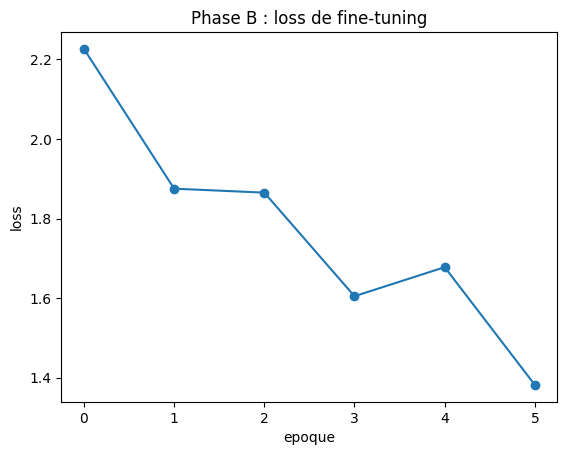


=========== RESULTATS (jeu de TEST, articles jamais vus) ===========
1. avant entrainement        MAE 2.44 | niveau 0.33 | AUC 0.49 | intrus 0.29 (dont accessoire 0.21) | remplacement top-5 0.23 (hasard 0.28)
                             article repare : la note monte dans 0.06 des cas (gain moyen -0.0)
2. transformer entraine      MAE 2.64 | niveau 0.44 | AUC 0.73 | intrus 0.37 (dont accessoire 0.40) | remplacement top-5 0.69 (hasard 0.32)
                             article repare : la note monte dans 0.62 des cas (gain moyen +1.6)
3. apres fine-tuning CLIP    MAE 2.64 | niveau 0.44 | AUC 0.73 | intrus 0.37 (dont accessoire 0.40) | remplacement top-5 0.69 (hasard 0.32)
                             article repare : la note monte dans 0.62 des cas (gain moyen +1.6)


In [12]:
# %% PHASE B : fine-tuning des 2 derniers blocs de CLIP. Si la validation ne s'ameliore pas -> on ANNULE.
EPOCHS_B, PAIRS_B, REP_B = 6, 8, 2
state_A = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}      # sauvegarde avant fine-tuning
E_A = E
val_A = evaluate(model, E_A, val_samples, CATALOG_VAL)["AUC"] if select_ok else None
v = model.visual
unfrozen = list(v.transformer.resblocks[-2:].parameters()) + list(v.ln_post.parameters()) + [v.proj]
for p in unfrozen:
    p.requires_grad = True
print(f"fine-tuning : {sum(p.numel() for p in unfrozen) / 1e6:.1f} M parametres de CLIP degeles")
head_params = [p for n, p in model.named_parameters() if not n.startswith("visual.")]
opt = torch.optim.AdamW([{"params": unfrozen, "lr": 1e-5}, {"params": head_params, "lr": 1e-4}], weight_decay=0.01)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
hist_b = []
random.seed(2)
for ep in range(EPOCHS_B):
    model.train()
    pairs = draw_pairs(pool_train, REP_B); random.shuffle(pairs); tot = nb = 0
    for i in range(0, len(pairs), PAIRS_B):
        items, mask, y, odd, margin = pair_batch(pairs[i:i + PAIRS_B])
        imgs = IMG[items.view(-1)].to(dev).float()
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            emb = model.encode_images(imgs).view(len(items), K, -1)
            score, ol = model(emb, mask.to(dev))
            loss = pair_loss(score.float(), ol.float(), y.to(dev), odd.to(dev), margin.to(dev))
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item(); nb += 1
    hist_b.append(tot / nb)
    print(f"fine-tuning epoque {ep + 1}/{EPOCHS_B}  loss train {hist_b[-1]:.3f}")
E_ft = compute_table(model)
val_B = evaluate(model, E_ft, val_samples, CATALOG_VAL)["AUC"] if select_ok else None
if select_ok and val_B < val_A - 0.01:
    model.load_state_dict(state_A); E_final, FT_USED = E_A, False
    print(f"fine-tuning ANNULE : AUC val {val_B:.2f} < {val_A:.2f} (phase A conservee)")
else:
    E_final, FT_USED = E_ft, True
    print(f"fine-tuning conserve (AUC val {val_A} -> {val_B})")
del state_A
results["3. apres fine-tuning CLIP"] = evaluate(model, E_final, test_samples, CATALOG_TEST)
plt.plot(hist_b, marker="o"); plt.xlabel("epoque"); plt.ylabel("loss"); plt.title("Phase B : loss de fine-tuning"); plt.show()
print("\n=========== RESULTATS (jeu de TEST, articles jamais vus) ===========")
for name, m in results.items():
    show(name, m)

In [13]:
# %% VERIFICATION D'ACCESSOIRE : cas reels (vraie tenue + vrai accessoire) vs faux (accessoire d'une saison opposee)
def make_acc_cases(pool, n_neg=3, seed=7):
    rng = random.Random(seed); cases = []
    for of in pool:
        clothes, accs = split_items(of)
        if not clothes or not accs: continue
        base = clothes[:4]
        for acc in accs:
            cases.append((base, acc, 1))
            far = [it for o2 in pool if seasons_disjoint(o2["season"], of["season"]) for it in o2["items"]
                   if it not in of["items"]]
            c = [it for it in far if CAT[it] == CAT[acc]] or [it for it in far if CAT[it] in ACC_CATS]
            for neg in rng.sample(c, min(n_neg, len(c))):
                cases.append((base, neg, 0))
    return cases

@torch.no_grad()
def acc_signals(cases, E):
    rows = []
    for base, acc, y in cases:
        r = core.check_accessory(model, E[base], E[acc])
        rows.append((r["delta"], r["p_odd"], y))
    return np.array(rows)

def calibrate(sig):                              # cherche les seuils qui maximisent la precision equilibree
    d, p, y = sig[:, 0], sig[:, 1], sig[:, 2].astype(int)
    best = None
    for tp in np.arange(0.1, 0.91, 0.05):
        for td in np.arange(-3, 2.01, 0.25):
            pred = (p < tp) & (d > td)
            bal = (pred[y == 1].mean() + (~pred)[y == 0].mean()) / 2
            if best is None or bal > best[0] + 1e-9: best = (bal, float(tp), float(td))
    return best

acc_val, acc_test = make_acc_cases(pool_val), make_acc_cases(pool_test)
def n_pos_neg(c): return sum(x[2] == 1 for x in c), sum(x[2] == 0 for x in c)
print("cas accessoire  val (vrai, faux) :", n_pos_neg(acc_val), "| test :", n_pos_neg(acc_test))
ACC_THR = dict(core.DEFAULT_THR)
pv, nv = n_pos_neg(acc_val)
if pv >= 5 and nv >= 5:
    bal, tp, td = calibrate(acc_signals(acc_val, E_final))
    ACC_THR = dict(p_odd=tp, delta=td)
    print(f"seuils calibres sur la validation : p_odd < {tp:.2f} et delta > {td:+.2f}  (precision equilibree val {bal:.2f})")
else:
    print("ATTENTION : trop peu de cas accessoire en validation -> seuils par defaut (non calibres). Ajoute des archives.")

pt, nt = n_pos_neg(acc_test)
if pt >= 3 and nt >= 3:
    sig = acc_signals(acc_test, E_final)
    d, p, y = sig[:, 0], sig[:, 1], sig[:, 2].astype(int)
    pred = (p < ACC_THR["p_odd"]) & (d > ACC_THR["delta"])
    print(f"TEST accessoire ({len(y)} cas) : precision equilibree {((pred[y == 1].mean() + (~pred)[y == 0].mean()) / 2):.2f} | "
          f"AUC delta {auc_score(y, d):.2f} | AUC (1 - p_odd) {auc_score(y, -p):.2f}")
    if len(y) < 20: print("(moins de 20 cas : resultat indicatif seulement)")
else:
    print("Pas assez de cas accessoire dans le test pour mesurer. Ajoute des archives dans SHARDS.")

cas accessoire  val (vrai, faux) : (24, 20) | test : (31, 79)
seuils calibres sur la validation : p_odd < 0.10 et delta > -1.50  (precision equilibree val 0.90)
TEST accessoire (110 cas) : precision equilibree 0.56 | AUC delta 0.58 | AUC (1 - p_odd) 0.58


In [14]:
# %% RESULTAT FINAL : note + verdict + remplacements OU ajout d'accessoire (une seule fonction pour tout)
def outfit_odd(items, E):
    model.eval(); t = torch.tensor([items], device=dev)
    _, ol = model(E[t], torch.ones_like(t, dtype=torch.bool))
    return int(ol.argmax(1))                              # 0 = aucun intrus, sinon position + 1

def verdict_of(s):
    if s >= 8: return "EXCELLENT", "green"
    if s >= 5: return "PASSABLE", "orange"
    return "POOR", "red"

def apply_swap(items, p, c):
    return items + [c] if p == len(items) else items[:p] + [c] + items[p + 1:]

@torch.no_grad()
def propose(items, E, catalog, top=3, min_gain=0.3):
    """Retourne (note, [(pos, article)], [nouvelles notes]). pos == len(items) -> AJOUT d'un accessoire."""
    old = core.score_rows(model, E, [items])[0].item()
    if old >= 8:
        return old, [], []
    rows, meta = [], []
    for pos, it in enumerate(items):                      # 1) remplacer un article par un article de meme categorie
        if CAT[it] == "other": continue
        for c in catalog.get(CAT[it], []):
            if c not in items:
                rows.append(apply_swap(items, pos, c)); meta.append((pos, c))
    if len(items) < K and not any(CAT[i] in ACC_CATS for i in items):      # 2) ajouter un accessoire (4 -> 5)
        for cat_ in sorted(ACC_CATS):
            for c in catalog.get(cat_, []):
                rows.append(items + [c]); meta.append((len(items), c))
    if not rows:
        return old, [], []
    sc = core.score_rows(model, E, rows).tolist()
    order = [i for i in sorted(range(len(sc)), key=lambda i: -sc[i]) if sc[i] - old >= min_gain][:top]
    return old, [meta[i] for i in order], [sc[i] for i in order]

def draw_review(items, old, swaps, new_scores, status):
    max_items = max([len(items)] + [len(items) + (1 if p == len(items) else 0) for p, _ in swaps])
    ncols, rows = max_items + 1, 1 + len(swaps)
    fig, axs = plt.subplots(rows, ncols, figsize=(2.6 * ncols, 3.2 * rows), squeeze=False)
    for ax in axs.flat: ax.axis("off")
    def draw_row(r, its, head, score, marks=(), mark_color="red", note=""):
        for j, it in enumerate(its):
            ax = axs[r][j]
            ax.imshow(Image.open(f"{OUT}/{used[it]}.jpg")); ax.set_title(f"[{CAT[it]}] " + DESC[it][:22], fontsize=8)
            if j in marks:
                ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
                for sp in ax.spines.values(): sp.set_edgecolor(mark_color); sp.set_linewidth(4)
        v, c = verdict_of(score); tx = axs[r][ncols - 1]; tx.axis("off")
        tx.text(0, 0.65, head, fontsize=10, weight="bold")
        tx.text(0, 0.40, f"Score {score:.1f}/10{note}", fontsize=12, weight="bold", color=c)
        tx.text(0, 0.18, v + (" - VALIDATED" if score >= 8 else ""), fontsize=11, weight="bold", color=c)
    draw_row(0, items, "ORIGINAL OUTFIT", old, marks={p for p, _ in swaps}, mark_color="red")
    for k, ((pos, c), s) in enumerate(zip(swaps, new_scores)):
        draw_row(k + 1, apply_swap(items, pos, c), f"WITH SUGGESTION {k + 1}" + (" (ADD)" if pos == len(items) else ""),
                 s, marks={pos}, mark_color="green", note=f" ({s - old:+.1f})")
    if status == "validated": fig.suptitle("OUTFIT VALIDATED: no change needed", color="green", fontweight="bold")
    elif status == "none": fig.suptitle("No replacement improves this outfit", color="darkorange", fontweight="bold")
    else: fig.suptitle("Red border = item to replace  |  Green border = suggested item / accessory", fontsize=10)
    plt.show()

def review(items, E, catalog=None, top=3, min_gain=0.3):
    old, swaps, new_scores = propose(items, E, catalog or CATALOG_ALL, top, min_gain)
    draw_review(items, old, swaps, new_scores, "validated" if old >= 8 else ("improve" if swaps else "none"))

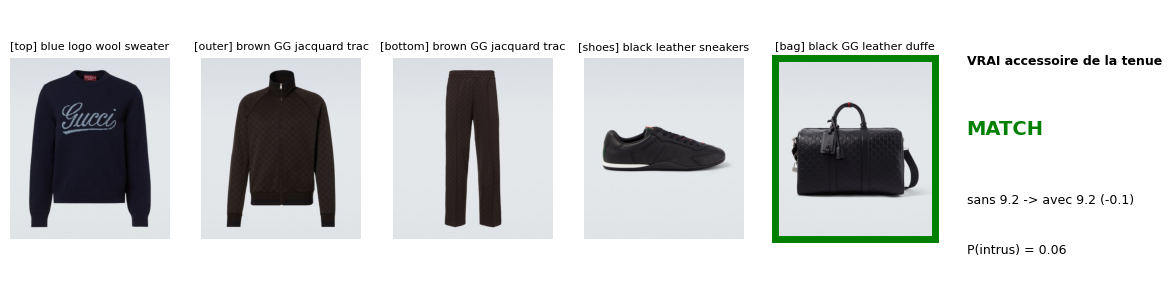

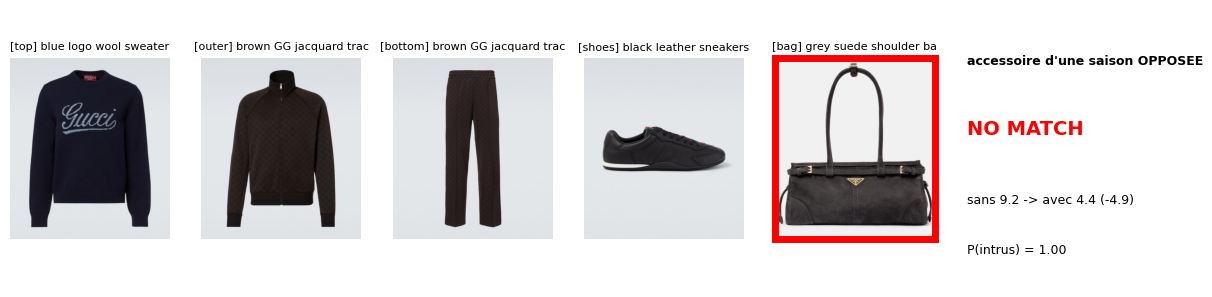

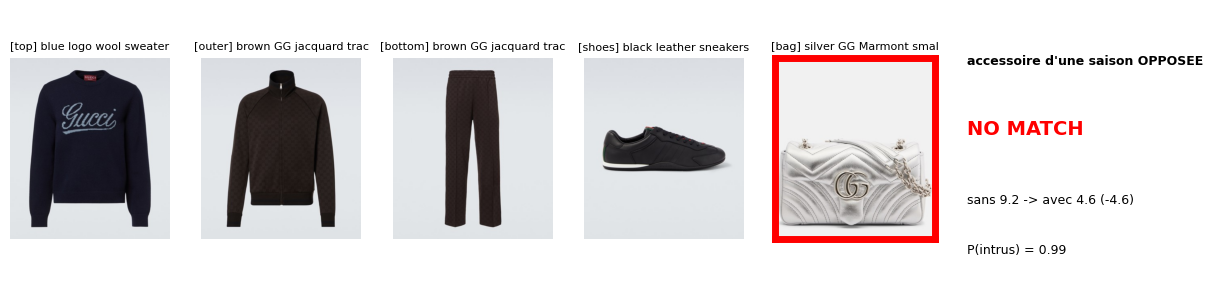

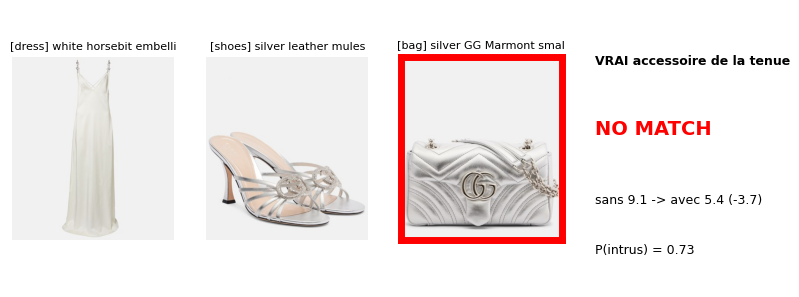

--- tenue de test (niveau reel : 2) ---


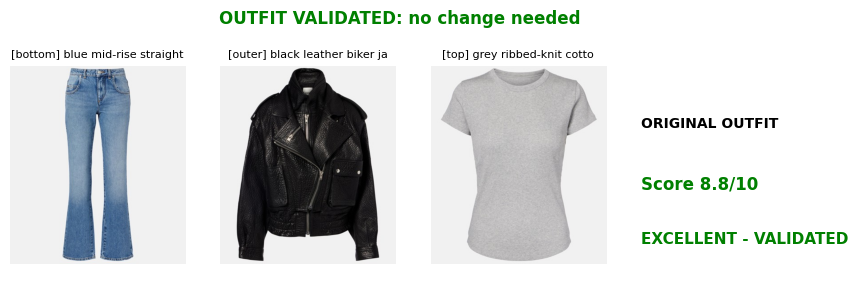

--- tenue de test (niveau reel : 1) ---


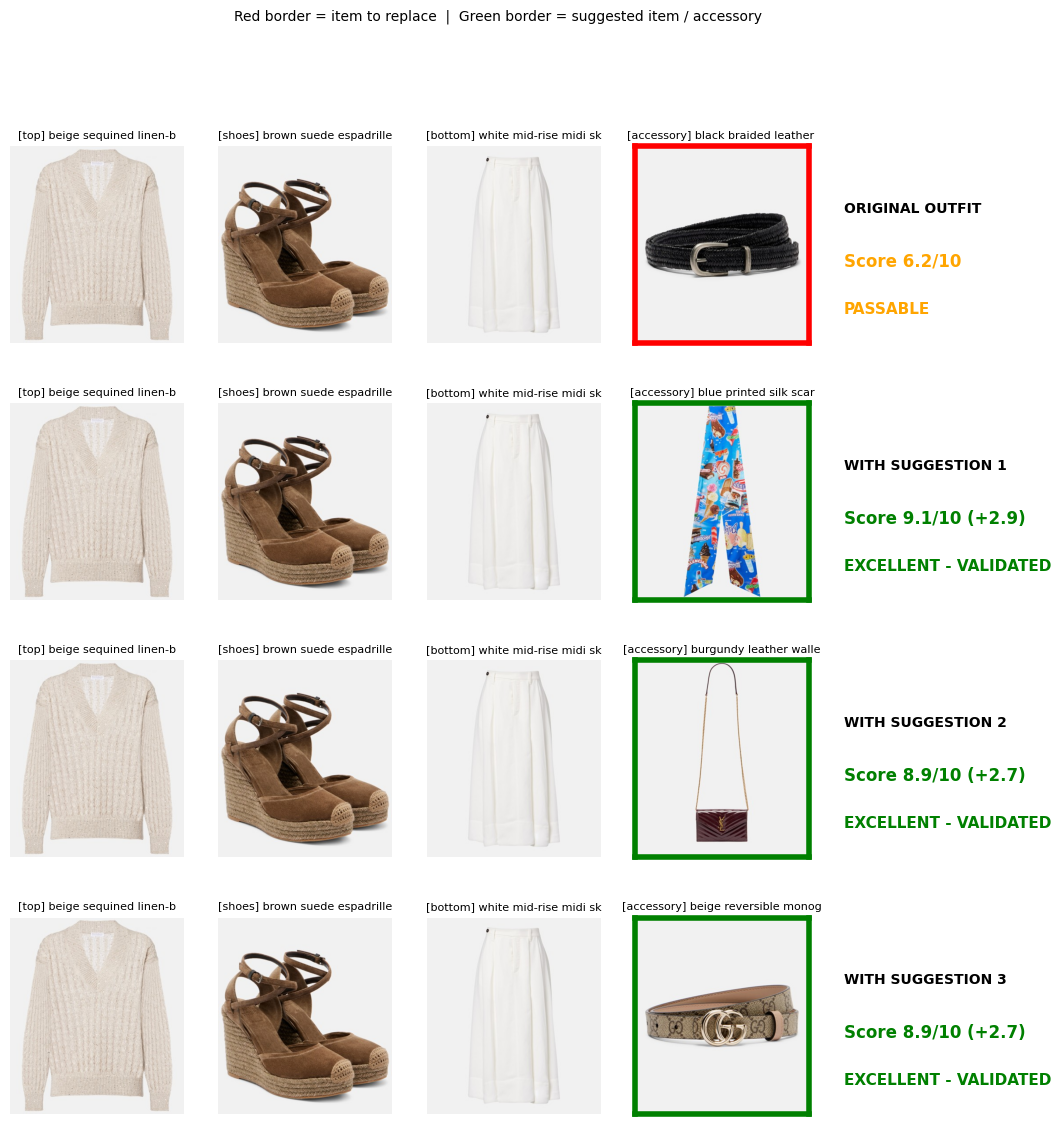

--- tenue de test (niveau reel : 0) ---


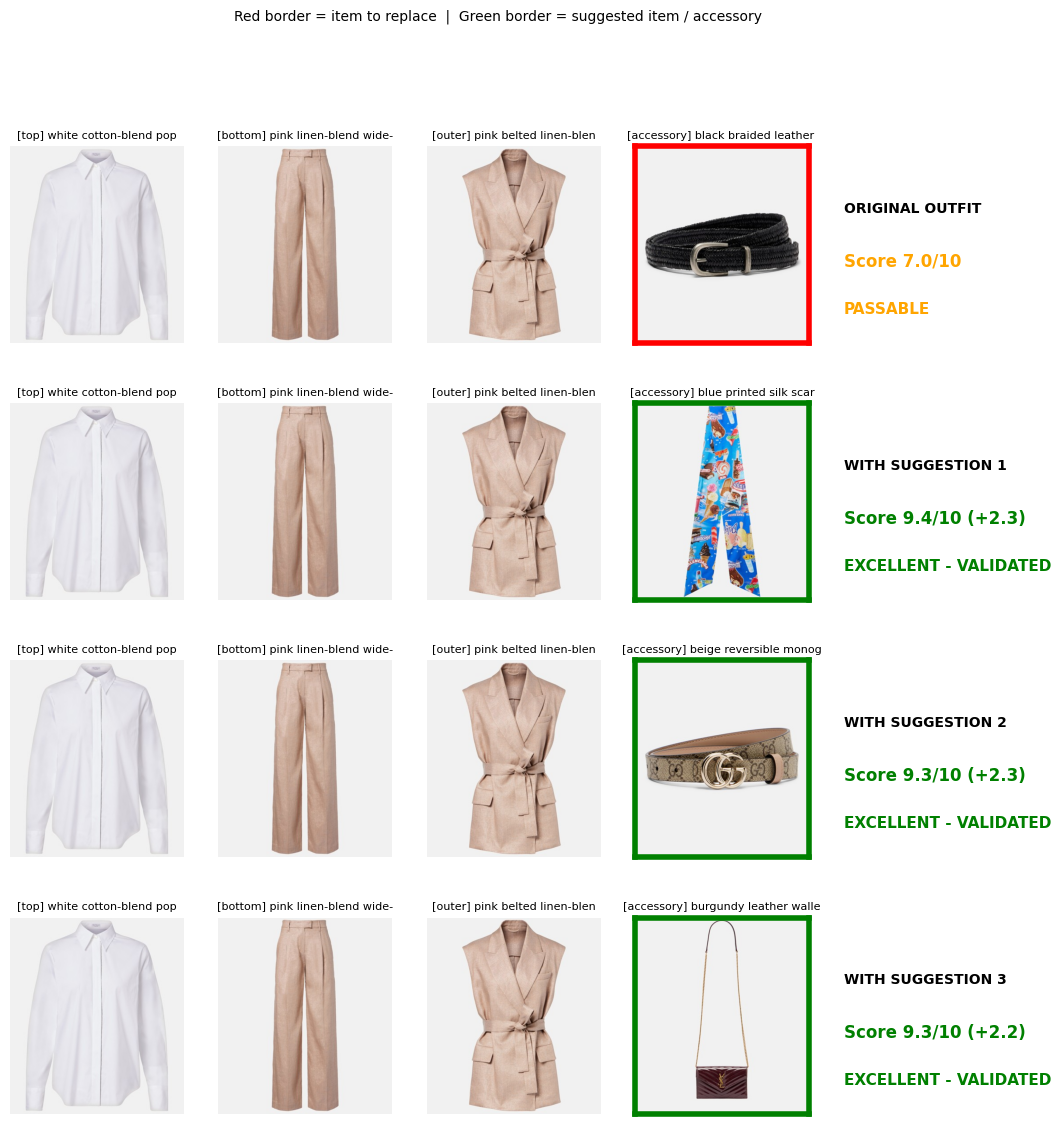

In [15]:
# %% DEMO 1 : l'utilisateur AJOUTE un accessoire -> match ou non ?
def show_accessory_check(base, acc, E, title=""):
    base = [i for i in base if CAT[i] not in ACC_CATS][:4]
    r = core.check_accessory(model, E[base], E[acc], ACC_THR)
    col = {"MATCH": "green", "BORDERLINE": "darkorange", "NO MATCH": "red"}[r["verdict"]]
    n = len(base) + 1
    fig, axs = plt.subplots(1, n + 1, figsize=(2.4 * (n + 1), 3.6))
    for ax in axs: ax.axis("off")
    for j, it in enumerate(base + [acc]):
        axs[j].imshow(Image.open(f"{OUT}/{used[it]}.jpg")); axs[j].set_title(f"[{CAT[it]}] " + DESC[it][:22], fontsize=8)
    axs[n - 1].axis("on"); axs[n - 1].set_xticks([]); axs[n - 1].set_yticks([])
    for sp in axs[n - 1].spines.values(): sp.set_edgecolor(col); sp.set_linewidth(5)
    axs[n].text(0, 0.80, title, fontsize=9, weight="bold")
    axs[n].text(0, 0.55, r["verdict"], fontsize=14, weight="bold", color=col)
    axs[n].text(0, 0.30, f"sans {r['score_without']:.1f} -> avec {r['score_with']:.1f} ({r['delta']:+.1f})", fontsize=9)
    axs[n].text(0, 0.12, f"P(intrus) = {r['p_odd']:.2f}", fontsize=9)
    plt.show(); return r

demo_cases = acc_test[:4] if acc_test else acc_val[:4]
if not demo_cases:
    print("Aucun cas accessoire disponible : ajoute des archives dans SHARDS.")
for base, acc, y in demo_cases:
    show_accessory_check(base, acc, E_final, "VRAI accessoire de la tenue" if y else "accessoire d'une saison OPPOSEE")

# %% DEMO 2 : une tenue de chaque niveau (suggestions de remplacement ou d'ajout)
for tier_score in (9.0, 6.0, 2.0):
    s = next((sm for sm in test_samples if sm["score"] == tier_score), None)
    if s is None: print(f"(pas d'exemple de niveau {tier_of(tier_score)} dans le test)"); continue
    print(f"--- tenue de test (niveau reel : {tier_of(tier_score)}) ---")
    review(s["items"], E_final)

LLM_NAME = Qwen/Qwen2.5-3B-Instruct


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

--- tenue de test (niveau reel : 2) ---


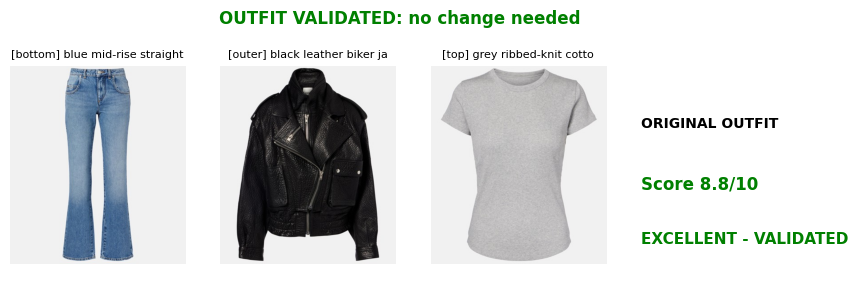

STYLISTE : The outfit works well as the jeans and jacket complement each other nicely. Adding a pair of white sneakers could help complete the look, improving comfort and style.
Garde-fou : OK, aucun chiffre invente 

--- tenue de test (niveau reel : 1) ---


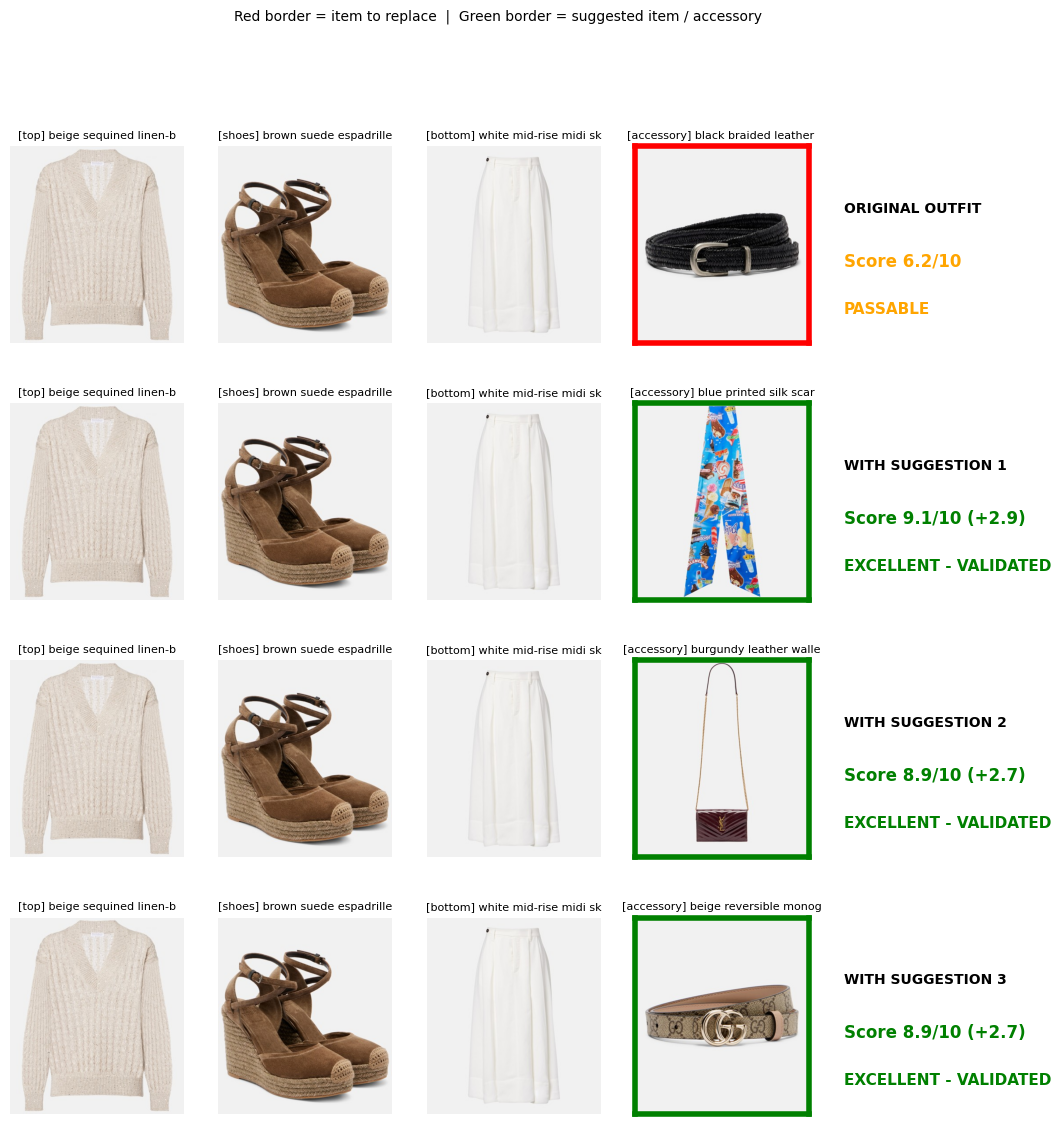

STYLISTE : The outfit lacks balance with the odd black braided leather belt. Replacing it with a blue printed silk scarf improves the score significantly by adding color and texture.
Previous look: null
Garde-fou : OK, aucun chiffre invente 

--- tenue de test (niveau reel : 0) ---


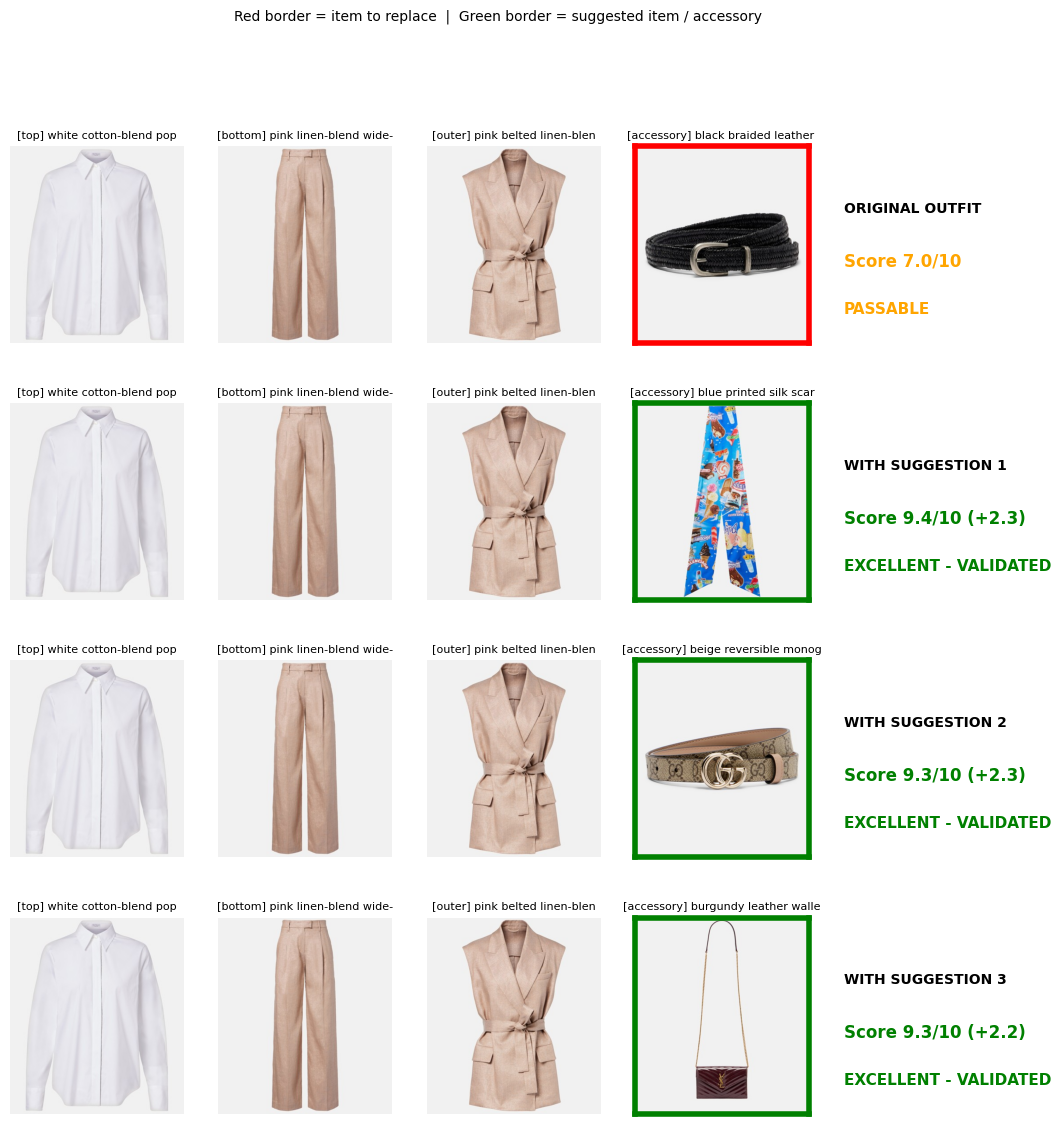

STYLISTE : The outfit works well but lacks color contrast. Replacing the black braided leather belt with a blue printed silk scarf improves it significantly.
Previous look: null
Garde-fou : OK, aucun chiffre invente 



In [16]:
# %% LLM STYLISTE (Qwen2.5-3B, gratuit). Le LLM n'invente RIEN : note, intrus, suggestions, tendance viennent du modele.
import glob
from transformers import AutoTokenizer, AutoModelForCausalLM
LANG = "English"           # "French" possible, mais le petit modele est plus fiable en anglais
cfg = [c for c in glob.glob("/kaggle/input/**/config.json", recursive=True) if "qwen" in c.lower()]
LLM_NAME = os.path.dirname(cfg[0]) if cfg else "Qwen/Qwen2.5-3B-Instruct"
print("LLM_NAME =", LLM_NAME)
tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.float16).to(dev).eval()

SYSTEM = ("You are a concise fashion stylist. A neural model has ALREADY scored the outfit. "
          "Never invent or change the score, the odd item or the suggestions: they are facts. "
          "Explain in at most 3 short sentences why the outfit works or not, using only the item descriptions given, "
          "then say which suggestion helps most (a suggestion with action 'add' means adding an accessory). "
          "Mention a previous look ONLY by repeating the field trend_vs_previous_look; if it is null say nothing about it. "
          f"Write in {LANG}. No markdown.")
MEMORY = []

@torch.no_grad()
def ask_llm(facts):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": json.dumps(facts)}]
    prompt = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
    inputs = tok(prompt, return_tensors="pt").to(dev)
    out = llm.generate(**inputs, max_new_tokens=160, do_sample=False)
    return tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def explain(items, E, catalog=None):
    old, swaps, new_scores = propose(items, E, catalog or CATALOG_ALL)
    odd = outfit_odd(items, E)
    prev = MEMORY[-1]["score"] if MEMORY else None
    trend = None if prev is None else ("higher than the previous look" if old > prev + 0.3 else
                                       "lower than the previous look" if old < prev - 0.3 else "similar to the previous look")
    def act(p, c):
        return dict(action="add", item=DESC[c]) if p == len(items) else dict(action="replace", replace=DESC[items[p]], by=DESC[c])
    facts = dict(outfit=[DESC[i] for i in items], score=round(old, 1),
                 odd_item=DESC[items[odd - 1]] if odd > 0 else None,
                 suggestions=[dict(**act(p, c), new_score=round(s, 1)) for (p, c), s in zip(swaps, new_scores)],
                 trend_vs_previous_look=trend)
    try:
        text = ask_llm(facts)
    except Exception as e:
        text = f"(LLM indisponible : {e!r}) Note du modele : {old:.1f}/10."
    allowed = set(re.findall(r"\d+(?:\.\d+)?", json.dumps(facts))) | {"10", "8", "5"}     # garde-fou : aucun chiffre invente
    invented = [n for n in re.findall(r"\d+(?:\.\d+)?", text) if n not in allowed]
    MEMORY.append(dict(outfit=facts["outfit"], score=facts["score"])); del MEMORY[:-5]
    return text, invented

for tier_score in (9.0, 6.0, 2.0):
    s = next((sm for sm in test_samples if sm["score"] == tier_score), None)
    if s is None: continue
    print(f"--- tenue de test (niveau reel : {tier_of(tier_score)}) ---")
    review(s["items"], E_final)
    text, invented = explain(s["items"], E_final)
    print("STYLISTE :", text)
    print("Garde-fou :", "OK, aucun chiffre invente" if not invented else f"ATTENTION chiffres non issus du modele : {invented}", "\n")

In [17]:
# %% EXPORT POUR L'INTERFACE : tout ce qu'il faut pour noter un article DEJA au catalogue ET une photo NOUVELLE
D = "/kaggle/working/dressme_data"; os.makedirs(f"{D}/img", exist_ok=True)
for c in used:
    im = Image.open(f"{OUT}/{c}.jpg"); im.thumbnail((320, 320)); im.save(f"{D}/img/{c}.jpg", quality=85)
json.dump(dict(codes=used, desc=DESC, cat=CAT), open(f"{D}/catalog.json", "w"))
split_of = {id(o): s for s, pool in (("train", pool_train), ("val", pool_val), ("test", pool_test)) for o in pool}
json.dump([dict(items=o["items"], season=sorted(o["season"]), style=o["style_txt"], colors=o["colors"], split=split_of[id(o)])
           for o in raw_outfits], open(f"{D}/outfits.json", "w"))
E_final = compute_table(model)                                           # recalcule avec les poids FINAUX
np.save(f"{D}/emb_clip.npy", E0.cpu().numpy())                           # CLIP d'origine (texte <-> image)
np.save(f"{D}/emb_ft.npy", E_final.cpu().numpy())                        # CLIP fine-tune (pour la note)
torch.save({k: v.cpu() for k, v in model.state_dict().items() if not k.startswith("visual.")}, f"{D}/scorer.pt")
torch.save({k: v.half().cpu() for k, v in model.visual.state_dict().items()}, f"{D}/visual.pt")   # NOUVEAU : CLIP fine-tune
json.dump(dict(clip_name="ViT-B-32", clip_pretrained="laion2b_s34b_b79k", scorer=SCORER_CFG, K=K,
               acc_cats=sorted(ACC_CATS), acc_thr=ACC_THR, finetuned=FT_USED), open(f"{D}/config.json", "w"), indent=1)
shutil.copy("/kaggle/working/dressme_core.py", f"{D}/dressme_core.py")
shutil.make_archive("/kaggle/working/dressme_data", "zip", D)
print("OK -> telecharge /kaggle/working/dressme_data.zip et dezippe-le dans dressme/data/")
print("Dans l'interface :  import dressme_core as core ; model, pre, cfg = core.load_scorer('dressme/data')")

OK -> telecharge /kaggle/working/dressme_data.zip et dezippe-le dans dressme/data/
Dans l'interface :  import dressme_core as core ; model, pre, cfg = core.load_scorer('dressme/data')


In [18]:
# %% TEST ALLER-RETOUR : l'export, recharge comme le fera l'interface, donne-t-il les memes resultats ?
core_model, core_pre, core_cfg = core.load_scorer(D, dev)
idx = random.Random(0).sample(range(len(used)), 8)
ims = [Image.open(f"{D}/img/{used[i]}.jpg") for i in idx]                 # miniatures 320 px = "photos uploadees"
V = core.embed_images(core_model, core_pre, ims)
cos = (V.cpu() * E_final[idx].cpu()).sum(-1)
print("similarite vecteur recharge / vecteur du notebook :", [round(float(c), 3) for c in cos])
a = core.check_accessory(core_model, V[:3], V[3], ACC_THR)                # chemin "interface" (photo -> vecteur -> verdict)
b = core.check_accessory(model, E_final[idx[:3]], E_final[idx[3]], ACC_THR)    # chemin "notebook"
print("interface :", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in a.items()})
print("notebook  :", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in b.items()})
ok = float(cos.min()) > 0.97 and abs(a["score_with"] - b["score_with"]) < 0.7
print("EXPORT OK : l'interface retrouvera les memes notes." if ok else "ATTENTION : ecart important entre export et notebook, ne pas integrer avant d'en trouver la cause.")
del core_model

similarite vecteur recharge / vecteur du notebook : [0.962, 0.925, 0.929, 0.919, 0.939, 0.958, 0.919, 0.954]
interface : {'verdict': 'MATCH', 'match': True, 'score_without': 3.4, 'score_with': 3.28, 'delta': -0.12, 'p_odd': 0.0, 'base_ok': False}
notebook  : {'verdict': 'MATCH', 'match': True, 'score_without': 3.42, 'score_with': 3.32, 'delta': -0.1, 'p_odd': 0.0, 'base_ok': False}
ATTENTION : ecart important entre export et notebook, ne pas integrer avant d'en trouver la cause.
